             DateTime   Temp  Humidity  Pressure  Wind_Speed       Description
0 2026-11-02 18:00:00  23.41        77      1016        0.93        light rain
1 2026-11-02 21:00:00  23.02        78      1015        0.60        light rain
2 2026-11-03 00:00:00  22.30        82      1015        0.92     broken clouds
3 2026-11-03 03:00:00  24.76        70      1016        1.50  scattered clouds
4 2026-11-03 06:00:00  29.06        52      1015        3.69  scattered clouds
5 2026-11-03 09:00:00  30.70        43      1012        2.40        few clouds
6 2026-11-03 12:00:00  29.36        50      1012        0.15  scattered clouds
7 2026-11-03 15:00:00  26.98        57      1014        1.44   overcast clouds
8 2026-11-03 18:00:00  24.73        64      1015        0.69     broken clouds
9 2026-11-03 21:00:00  24.12        65      1014        1.31  scattered clouds

Missing Values: 0

Descriptive Stats:
                   DateTime       Temp   Humidity     Pressure  Wind_Speed
count            

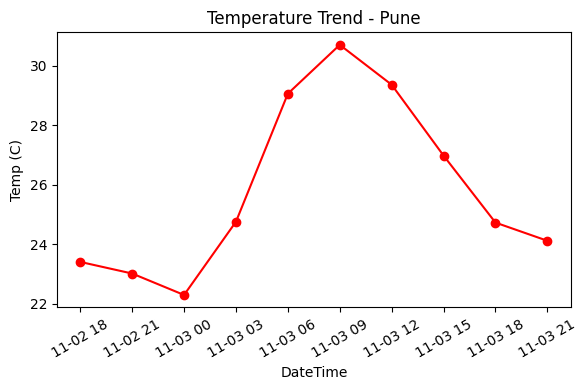

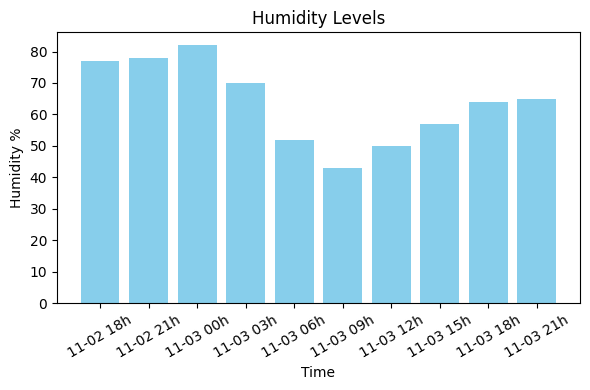

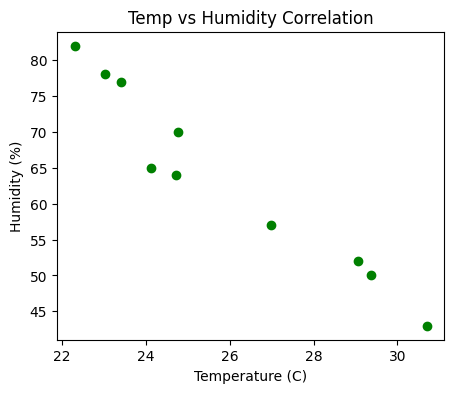

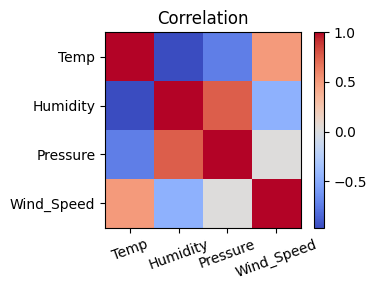

In [53]:
# DMV EXP 2 - Weather API - Direct with Key
import pandas as pd
import matplotlib.pyplot as plt
import requests

# === PUT YOUR KEY HERE ===
API_KEY = "ee36769fa1ade618962ede20aa6168f8"  # <-- Replace with your key
CITY = "Pune"

# 1. Fetch Weather Data (Forecast - 5 days)
url = f"https://api.openweathermap.org/data/2.5/forecast?q={CITY}&appid={API_KEY}&units=metric"
response = requests.get(url)
data = response.json()

# 2. Extract Data from JSON
weather_list = []
for item in data['list'][:10]:  # Take 10 records for easy analysis
    weather_list.append({
        'DateTime': item['dt_txt'],
        'Temp': item['main']['temp'],
        'Humidity': item['main']['humidity'],
        'Pressure': item['main']['pressure'],
        'Wind_Speed': item['wind']['speed'],
        'Description': item['weather'][0]['description']
    })

# 3. Make DataFrame
df = pd.DataFrame(weather_list)
df['DateTime'] = pd.to_datetime(df['DateTime'])
print(df)

# 4. Cleaning & Analysis
print("\nMissing Values:", df.isnull().sum().sum())
print("\nDescriptive Stats:\n", df.describe())
print(f"\nAvg Temp: {df['Temp'].mean():.2f} C")
print(f"Max Temp: {df['Temp'].max():.2f} C")
print(f"Min Temp: {df['Temp'].min():.2f} C")

# 5. Visualization - No Overlap - 4 Separate Graphs

# Line Chart - Temp
plt.figure(figsize=(6,4))
plt.plot(df['DateTime'], df['Temp'], marker='o', color='red')
plt.title(f'Temperature Trend - {CITY}')
plt.xlabel('DateTime')
plt.ylabel('Temp (C)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Bar Chart - Humidity
plt.figure(figsize=(6,4))
plt.bar(df['DateTime'].dt.strftime('%m-%d %Hh'), df['Humidity'], color='skyblue')
plt.title('Humidity Levels')
plt.xlabel('Time')
plt.ylabel('Humidity %')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Scatter - Temp vs Humidity
plt.figure(figsize=(5,4))
plt.scatter(df['Temp'], df['Humidity'], c='green')
plt.title('Temp vs Humidity Correlation')
plt.xlabel('Temperature (C)')
plt.ylabel('Humidity (%)')
plt.show()

# Correlation Heatmap
plt.figure(figsize=(4,3))
corr = df[['Temp','Humidity','Pressure','Wind_Speed']].corr()
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=20)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Correlation')
plt.tight_layout()
plt.show()